GRADIENT BOOSTING CLASSIFICATION
Dataset Shape: (150, 6)
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Missing values removed where required.
Number of samples: 150
Number of species: 3

Training samples: 120
Testing samples: 30

Model training completed!

Gradient Boosting Accuracy:
96.67%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                      

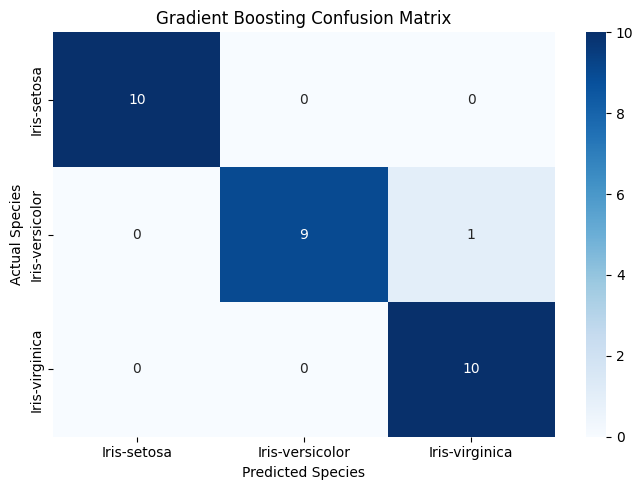

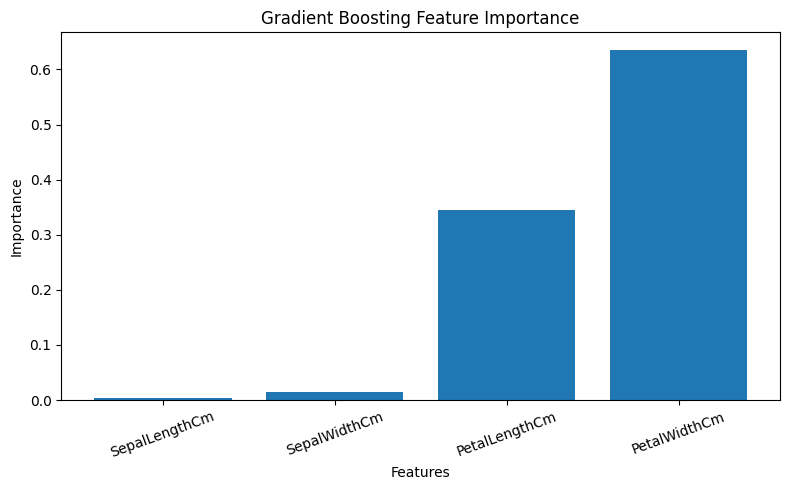


Feature Importance:
SepalLengthCm: 0.0036
SepalWidthCm: 0.0151
PetalLengthCm: 0.3457
PetalWidthCm: 0.6356

New Flower Measurements:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2

Predicted Species: Iris-setosa


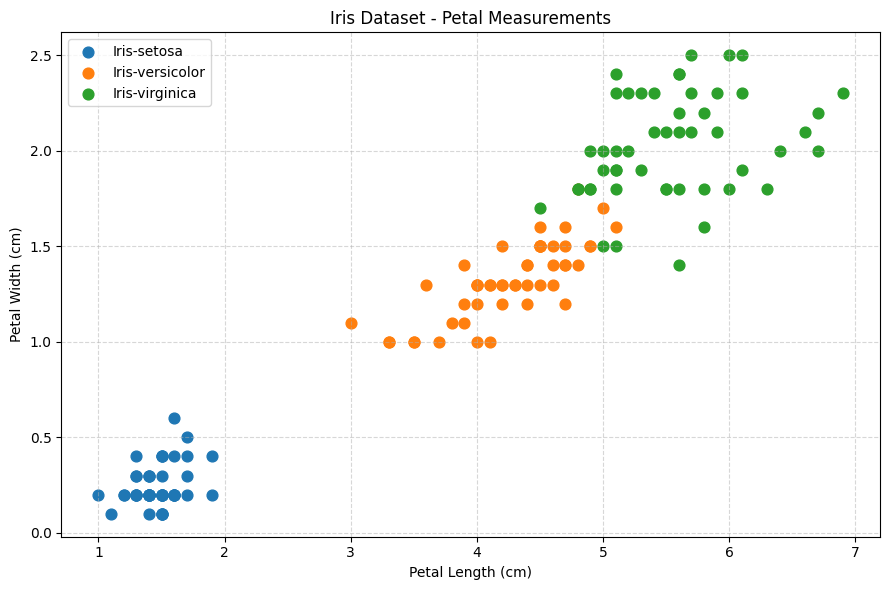


GRADIENT BOOSTING PROJECT COMPLETED SUCCESSFULLY


In [4]:

# GRADIENT BOOSTING CLASSIFICATION USING IRIS DATASET

import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. LOAD DATASET

files = glob.glob('/kaggle/input/datasets/uciml/iris/Iris.csv', recursive=True)

if not files:
    raise FileNotFoundError(
        "Iris.csv not found. Please add the Iris dataset to Kaggle."
    )

iris = pd.read_csv(files[0])

print("=" * 60)
print("GRADIENT BOOSTING CLASSIFICATION")
print("=" * 60)

print("Dataset Shape:", iris.shape)
print(iris.head())

# 2. CHECK REQUIRED COLUMNS

features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

target = "Species"

required_columns = features + [target]

missing_columns = [
    col for col in required_columns if col not in iris.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns not found: {missing_columns}"
    )

# 3. CLEAN DATA

iris = iris.dropna(subset=required_columns).copy()

X = iris[features]
y = iris[target]

print("\nMissing values removed where required.")
print("Number of samples:", len(iris))
print("Number of species:", y.nunique())

# 4. SPLIT DATA

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 5. CREATE GRADIENT BOOSTING MODEL

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# 6. TRAIN MODEL

gb_model.fit(X_train, y_train)

print("\nModel training completed!")

# 7. MAKE PREDICTIONS

y_pred = gb_model.predict(X_test)

# 8. CALCULATE ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("\nGradient Boosting Accuracy:")
print(f"{accuracy * 100:.2f}%")

# 9. CLASSIFICATION REPORT

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# 10. CONFUSION MATRIX

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=gb_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=gb_model.classes_,
    yticklabels=gb_model.classes_
)

plt.title("Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

# 11. FEATURE IMPORTANCE

importance = gb_model.feature_importances_

plt.figure(figsize=(8, 5))
plt.bar(features, importance)

plt.title("Gradient Boosting Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("\nFeature Importance:")

for feature, value in zip(features, importance):
    print(f"{feature}: {value:.4f}")

# 12. PREDICT A NEW FLOWER

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=features
)

prediction = gb_model.predict(new_flower)

print("\nNew Flower Measurements:")
print(new_flower)

print("\nPredicted Species:", prediction[0])

# 13. VISUALIZE THE IRIS DATASET

plt.figure(figsize=(9, 6))

for species in iris[target].unique():
    data = iris[iris[target] == species]

    plt.scatter(
        data["PetalLengthCm"],
        data["PetalWidthCm"],
        s=60,
        label=species
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Dataset - Petal Measurements")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# PROJECT COMPLETED

print("\n" + "=" * 60)
print("GRADIENT BOOSTING PROJECT COMPLETED SUCCESSFULLY")
print("=" * 60)
